In [1]:
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Same random numbers every run -> results are reproducible
torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True   # GPU gives the same result every run
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

CLASS_NAMES = ["N (Normal)", "S (Supra.)", "V (Ventr.)", "F (Fusion)", "Q (Unknown)"]

Using device: cuda


## 1. Load the data
The CSV files have no header. Columns 0–186 = signal, column 187 = label.

In [2]:
train_df = pd.read_csv("data/mitbih_train.csv", header=None)
test_df  = pd.read_csv("data/mitbih_test.csv",  header=None)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
train_df.head()

Train shape: (87554, 188)
Test shape : (21892, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


187
0.0    72471
1.0     2223
2.0     5788
3.0      641
4.0     6431
Name: count, dtype: int64

Percentage of Normal beats: 82.8%


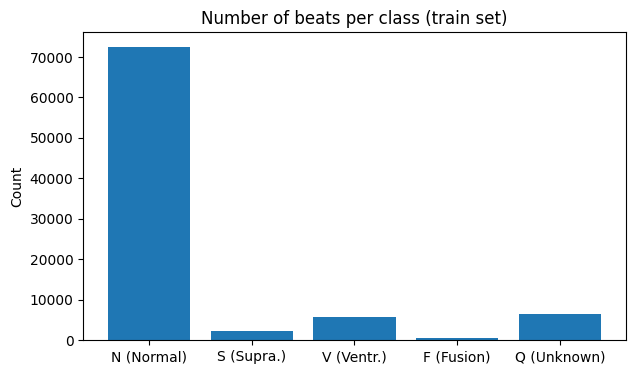

In [3]:
train_counts = train_df[187].value_counts().sort_index()
print(train_counts)
print("\nPercentage of Normal beats: %.1f%%" % (100 * train_counts[0] / len(train_df)))

plt.figure(figsize=(7, 4))
plt.bar(CLASS_NAMES, train_counts.values)
plt.title("Number of beats per class (train set)")
plt.ylabel("Count")
plt.show()

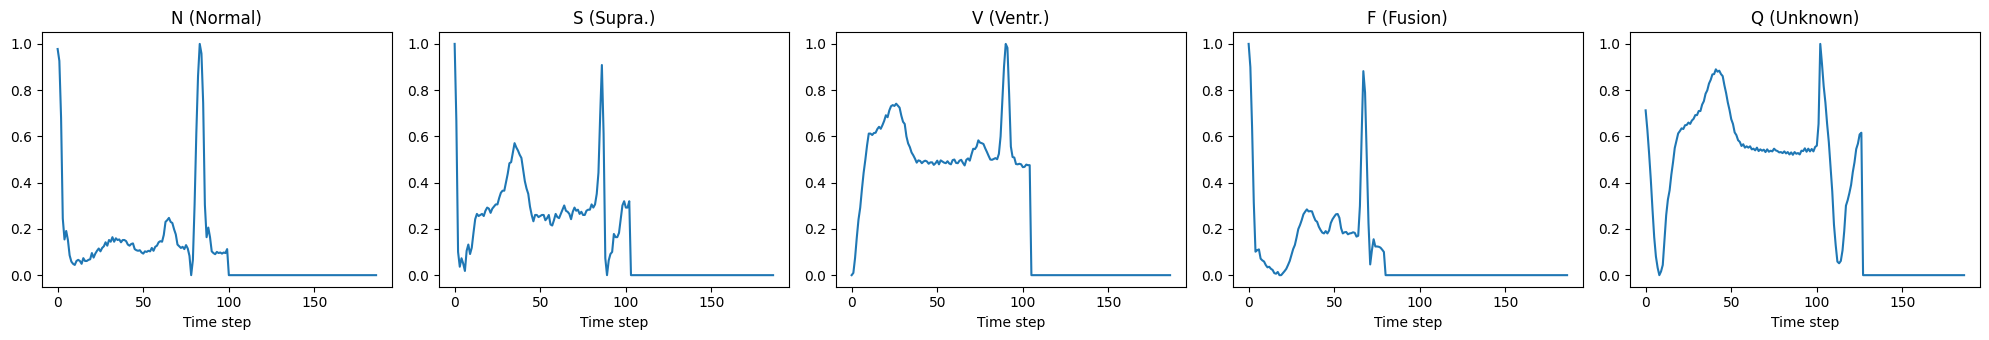

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))

for label in range(5):
    one_beat = train_df[train_df[187] == label].iloc[0, :187]   # first beat of this class
    axes[label].plot(one_beat.values)
    axes[label].set_title(CLASS_NAMES[label])
    axes[label].set_xlabel("Time step")

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 4))
for label in range(5):
    mean_beat = train_df[train_df[187] == label].iloc[:, :187].mean()
    plt.plot(mean_beat.values, label=CLASS_NAMES[label])

plt.title("Average beat of each class")
plt.xlabel("Time step")
plt.legend()
plt.show()

In [6]:
X = train_df.iloc[:, :187].values.astype(np.float32)
y = train_df[187].values.astype(np.int64)

X_test = test_df.iloc[:, :187].values.astype(np.float32)
y_test = test_df[187].values.astype(np.int64)

# Train / validation split (90% / 10%)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, stratify=y, random_state=42)

# Add the channel dimension: (N, 187) -> (N, 1, 187)
X_train = X_train[:, np.newaxis, :]
X_val   = X_val[:, np.newaxis, :]
X_test  = X_test[:, np.newaxis, :]

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

X_train: (78798, 1, 187)  X_val: (8756, 1, 187)  X_test: (21892, 1, 187)


In [7]:
BATCH_SIZE = 128

train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(torch.tensor(X_val),   torch.tensor(y_val)),   batch_size=BATCH_SIZE)
test_loader  = DataLoader(TensorDataset(torch.tensor(X_test),  torch.tensor(y_test)),  batch_size=BATCH_SIZE)

In [ ]:
def predict(model, loader):
    model.eval()                      
    all_preds = []
    with torch.no_grad():              
        for xb, _ in loader:
            outputs = model(xb.to(device))       
            preds = outputs.argmax(dim=1)          
            all_preds.append(preds.cpu().numpy())
    return np.concatenate(all_preds)


def train_model(model, epochs=15, lr=1e-3, class_weights=None):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_f1": []}
    best_f1, best_weights = 0, None
    start = time.time()

    for epoch in range(epochs):
        # ---- training ----
        model.train()
        total_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            outputs = model(xb)              # 1. forward pass
            loss = loss_fn(outputs, yb)      # 2. how wrong are we?

            optimizer.zero_grad()            # 3. clear old gradients
            loss.backward()                  # 4. compute new gradients
            optimizer.step()                 # 5. update the weights

            total_loss += loss.item() * len(xb)

        # ---- validation ----
        train_loss = total_loss / len(train_loader.dataset)
        val_f1 = f1_score(y_val, predict(model, val_loader), average="macro")
        history["train_loss"].append(train_loss)
        history["val_f1"].append(val_f1)
        print(f"Epoch {epoch+1:2d}/{epochs} | train loss {train_loss:.4f} | val macro F1 {val_f1:.4f}")

        # ---- keep the best model ----
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_weights = copy.deepcopy(model.state_dict())

    train_time = time.time() - start
    model.load_state_dict(best_weights)
    print(f"\nBest val macro F1: {best_f1:.4f} | training time: {train_time:.0f} s")
    return model, history, train_time


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].plot(history["train_loss"]); axes[0].set_title("Train loss"); axes[0].set_xlabel("Epoch")
    axes[1].plot(history["val_f1"]);     axes[1].set_title("Validation macro F1"); axes[1].set_xlabel("Epoch")
    fig.suptitle(title)
    plt.show()


results = []    # one row per experiment -> final comparison table


def evaluate_model(model, name, train_time):
    y_pred = predict(model, test_loader)

    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    recall_per_class = classification_report(y_test, y_pred, output_dict=True)
    n_params = sum(p.numel() for p in model.parameters())

    print(f"{name}  ->  Test accuracy: {acc:.4f} | Test macro F1: {macro_f1:.4f}\n")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

    # Confusion matrix (normalised per row = recall of each class)
    cm = confusion_matrix(y_test, y_pred, normalize="true")
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix — {name}")
    plt.show()

    row = {"Model": name, "Accuracy": acc, "Macro F1": macro_f1}
    for i, cname in enumerate(["N", "S", "V", "F", "Q"]):
        row[f"Recall {cname}"] = recall_per_class[str(i)]["recall"]
    row["Params"] = n_params
    row["Train time (s)"] = round(train_time)
    results.append(row)
    return pd.DataFrame(results)

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5, padding=2),  nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)       
        self.classifier = nn.Sequential(
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):            # x: (batch, 1, 187)
        x = self.features(x)         # (batch, 64, 23)
        x = self.pool(x)             # (batch, 64, 1)
        x = x.flatten(1)             # (batch, 64)
        return self.classifier(x)    # (batch, 5)


model_cnn = SimpleCNN()
print(model_cnn)
print("Trainable parameters:", sum(p.numel() for p in model_cnn.parameters()))

SimpleCNN(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (7): ReLU()
    (8): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool1d(output_size=1)
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=5, bias=True)
  )
)
Trainable parameters: 17477


C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Epoch  1/15 | train loss 0.5576 | val macro F1 0.3440


Epoch  2/15 | train loss 0.3603 | val macro F1 0.4544


Epoch  3/15 | train loss 0.3204 | val macro F1 0.4814


Epoch  4/15 | train loss 0.2954 | val macro F1 0.5149


...

Epoch 11/15 | train loss 0.1746 | val macro F1 0.7300


Epoch 12/15 | train loss 0.1689 | val macro F1 0.6858


Epoch 13/15 | train loss 0.1616 | val macro F1 0.7321


Epoch 14/15 | train loss 0.1569 | val macro F1 0.7690


Epoch 15/15 | train loss 0.1515 | val macro F1 0.7698

Best val macro F1: 0.7698 | training time: 43 s


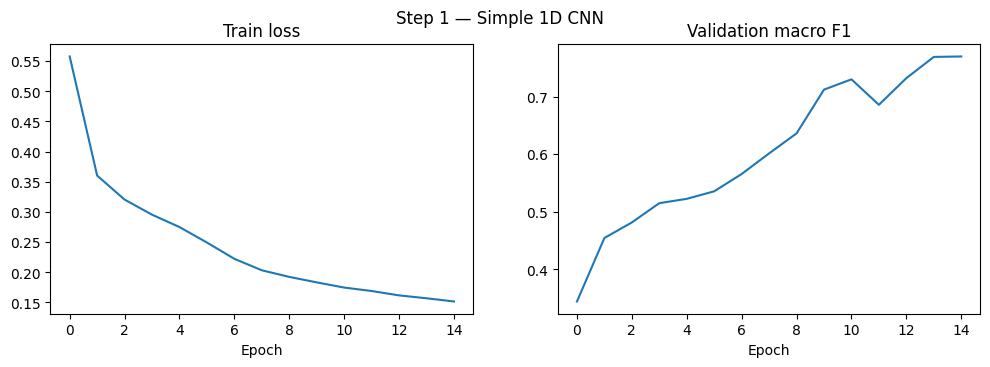

In [10]:
model_cnn, history_cnn, time_cnn = train_model(model_cnn, epochs=15)
plot_history(history_cnn, "Step 1 — Simple 1D CNN")

1. Simple CNN (baseline)  ->  Test accuracy: 0.9593 | Test macro F1: 0.7756

              precision    recall  f1-score   support

  N (Normal)      0.969     0.989     0.978     18118
  S (Supra.)      0.794     0.437     0.564       556
  V (Ventr.)      0.885     0.889     0.887      1448
  F (Fusion)      0.700     0.389     0.500       162
 Q (Unknown)      0.967     0.931     0.949      1608

    accuracy                          0.959     21892
   macro avg      0.863     0.727     0.776     21892
weighted avg      0.956     0.959     0.956     21892



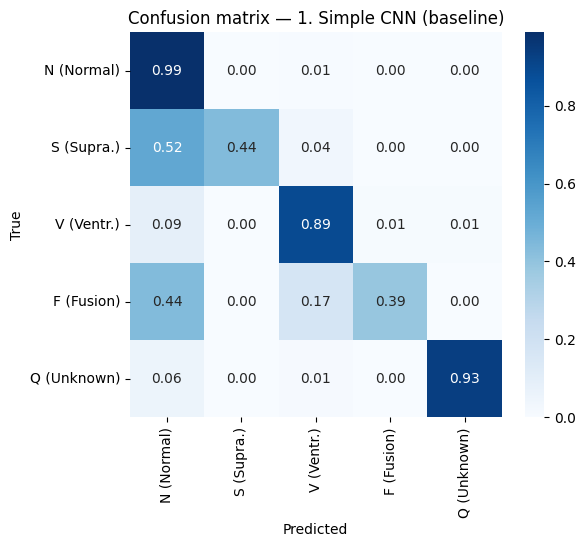

,Model,Accuracy,Macro F1,Recall N,Recall S,Recall V,Recall F,Recall Q,Params,Train time (s)
0,1. Simple CNN (baseline),0.959346,0.775585,0.98863,0.43705,0.888812,0.388889,0.93097,17477,43


In [11]:
evaluate_model(model_cnn, "1. Simple CNN (baseline)", time_cnn)

---
## Step 2 — Simple 1D CNN + Class Weights

**Only one change:** the loss function now gets **class weights**. Same model, same epochs, same learning rate.

**Idea:** a mistake on a rare class should cost more than a mistake on a Normal beat. We use the "balanced" formula:

$$w_c = \frac{\text{total samples}}{\text{number of classes} \times \text{samples in class } c}$$

So a rare class (F) gets a big weight and Normal gets a small weight. `CrossEntropyLoss(weight=...)` multiplies the loss of each sample by the weight of its true class.

In [12]:
counts = np.bincount(y_train)                          # samples per class
class_weights = len(y_train) / (5 * counts)            # balanced weights

print(pd.DataFrame({"Class": CLASS_NAMES, "Count": counts, "Weight": class_weights.round(2)}))

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

         Class  Count  Weight
0   N (Normal)  65223    0.24
1   S (Supra.)   2001    7.88
2   V (Ventr.)   5209    3.03
3   F (Fusion)    577   27.31
4  Q (Unknown)   5788    2.72


Epoch  1/15 | train loss 1.3795 | val macro F1 0.2366


Epoch  2/15 | train loss 0.9617 | val macro F1 0.4047


Epoch  3/15 | train loss 0.7731 | val macro F1 0.4517


Epoch  4/15 | train loss 0.6599 | val macro F1 0.5389


Epoch  5/15 | train loss 0.5955 | val macro F1 0.5393


...

Epoch 11/15 | train loss 0.4233 | val macro F1 0.6764


Epoch 12/15 | train loss 0.3950 | val macro F1 0.6745


Epoch 13/15 | train loss 0.3860 | val macro F1 0.6270


Epoch 14/15 | train loss 0.3740 | val macro F1 0.6059


Epoch 15/15 | train loss 0.3708 | val macro F1 0.6427

Best val macro F1: 0.6764 | training time: 42 s


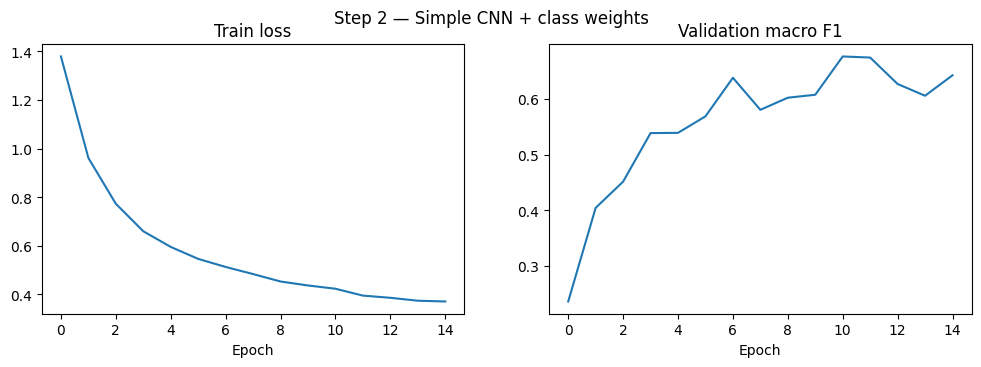

In [13]:
torch.manual_seed(42)                 # same starting weights as Step 1 -> fair comparison
model_cnn_w = SimpleCNN()

model_cnn_w, history_cnn_w, time_cnn_w = train_model(model_cnn_w, epochs=15, class_weights=class_weights_tensor)
plot_history(history_cnn_w, "Step 2 — Simple CNN + class weights")

2. Simple CNN + class weights  ->  Test accuracy: 0.8721 | Test macro F1: 0.6612

              precision    recall  f1-score   support

  N (Normal)      0.982     0.873     0.924     18118
  S (Supra.)      0.225     0.728     0.343       556
  V (Ventr.)      0.759     0.840     0.797      1448
  F (Fusion)      0.205     0.840     0.330       162
 Q (Unknown)      0.886     0.938     0.911      1608

    accuracy                          0.872     21892
   macro avg      0.611     0.844     0.661     21892
weighted avg      0.935     0.872     0.896     21892



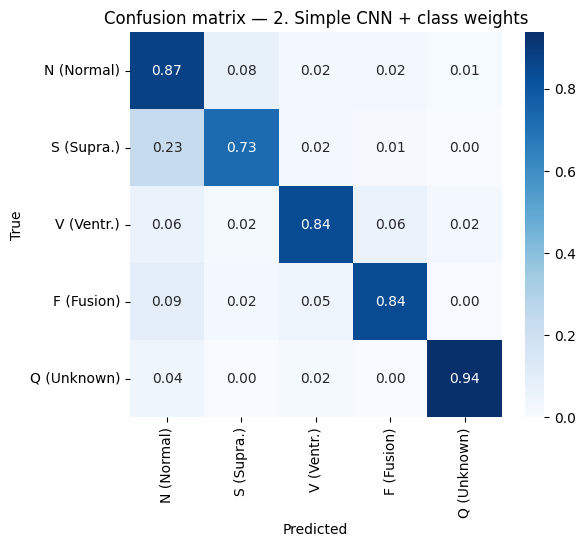

,Model,Accuracy,Macro F1,Recall N,Recall S,Recall V,Recall F,Recall Q,Params,Train time (s)
0,1. Simple CNN (baseline),0.959346,0.775585,0.988630,0.437050,0.888812,0.388889,0.930970,17477,43
1,2. Simple CNN + class weights,0.872054,0.661183,0.873496,0.728417,0.839779,0.839506,0.937811,17477,42


In [14]:
evaluate_model(model_cnn_w, "2. Simple CNN + class weights", time_cnn_w)

In [15]:
class CNNBiLSTMAttention(nn.Module):
    def __init__(self, n_classes=5):
        super().__init__()
        # 1. CNN: local shape detector
        self.cnn = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2),  nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
        )
        # 2. BiLSTM: reads the sequence in both directions
        self.lstm = nn.LSTM(input_size=64, hidden_size=64, batch_first=True, bidirectional=True)
        # 3. Attention: one score per time step
        self.attention = nn.Linear(128, 1)
        # 4. Classifier
        self.classifier = nn.Sequential(
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):                              # x: (batch, 1, 187)
        x = self.cnn(x)                                # (batch, 64, 46)
        x = x.permute(0, 2, 1)                         # (batch, 46, 64)  LSTM wants (batch, time, features)
        lstm_out, _ = self.lstm(x)                     # (batch, 46, 128)

        scores = self.attention(lstm_out)              # (batch, 46, 1)
        weights = torch.softmax(scores, dim=1)         # (batch, 46, 1)  sum over time = 1
        context = (weights * lstm_out).sum(dim=1)      # (batch, 128)    weighted average

        self.attention_weights = weights.squeeze(-1).detach()   # saved for plotting later
        return self.classifier(context)                # (batch, 5)


torch.manual_seed(42)
model_att = CNNBiLSTMAttention()
print(model_att)
print("Trainable parameters:", sum(p.numel() for p in model_att.parameters()))

CNNBiLSTMAttention(
  (cnn): Sequential(
    (0): Conv1d(1, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (attention): Linear(in_features=128, out_features=1, bias=True)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=5, bias=True)
  )
)
Trainable parameters: 85766


Epoch  1/15 | train loss 0.5528 | val macro F1 0.4158


Epoch  2/15 | train loss 0.3053 | val macro F1 0.5478


Epoch  3/15 | train loss 0.1971 | val macro F1 0.7431


Epoch  4/15 | train loss 0.1496 | val macro F1 0.8007


Epoch  5/15 | train loss 0.1289 | val macro F1 0.8505


...

Epoch 11/15 | train loss 0.0816 | val macro F1 0.8832


Epoch 12/15 | train loss 0.0777 | val macro F1 0.8773


Epoch 13/15 | train loss 0.0752 | val macro F1 0.8899


Epoch 14/15 | train loss 0.0705 | val macro F1 0.8919


Epoch 15/15 | train loss 0.0690 | val macro F1 0.8761

Best val macro F1: 0.8919 | training time: 58 s


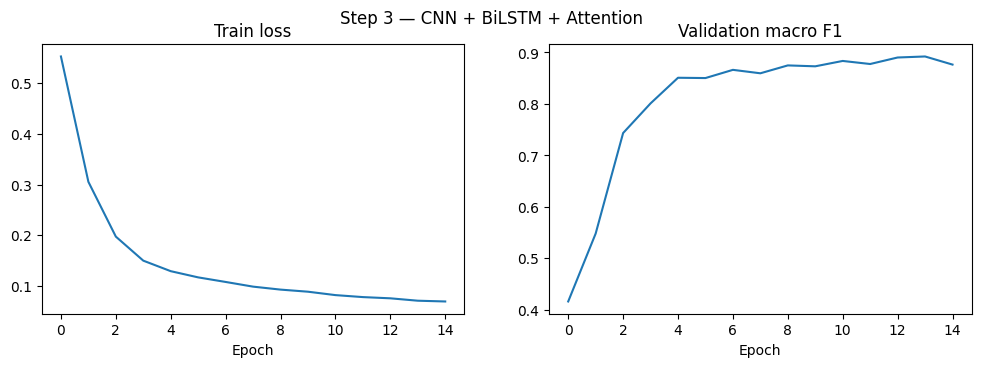

In [16]:
model_att, history_att, time_att = train_model(model_att, epochs=15)
plot_history(history_att, "Step 3 — CNN + BiLSTM + Attention")

3. CNN + BiLSTM + Attention  ->  Test accuracy: 0.9786 | Test macro F1: 0.8874

              precision    recall  f1-score   support

  N (Normal)      0.984     0.994     0.989     18118
  S (Supra.)      0.898     0.664     0.763       556
  V (Ventr.)      0.939     0.938     0.938      1448
  F (Fusion)      0.827     0.710     0.764       162
 Q (Unknown)      0.986     0.979     0.983      1608

    accuracy                          0.979     21892
   macro avg      0.927     0.857     0.887     21892
weighted avg      0.978     0.979     0.978     21892



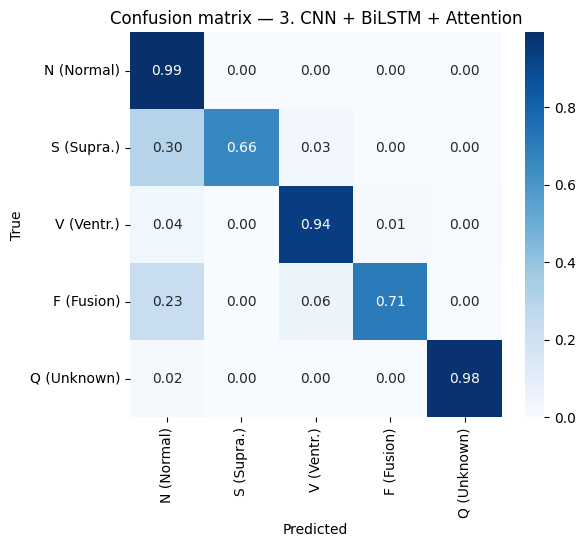

,Model,Accuracy,Macro F1,Recall N,Recall S,Recall V,Recall F,Recall Q,Params,Train time (s)
0,1. Simple CNN (baseline),0.959346,0.775585,0.988630,0.437050,0.888812,0.388889,0.930970,17477,43
1,2. Simple CNN + class weights,0.872054,0.661183,0.873496,0.728417,0.839779,0.839506,0.937811,17477,42
2,3. CNN + BiLSTM + Attention,0.978577,0.887445,0.993873,0.663669,0.937845,0.709877,0.978856,85766,58


In [17]:
evaluate_model(model_att, "3. CNN + BiLSTM + Attention", time_att)

### Where does the model look? — Attention visualisation
For one correctly classified test beat of each class, we plot the **ECG signal** (line) and the **attention weights** (shaded area).
The 46 attention steps are stretched back to the 187 samples of the signal so both can be drawn on the same x-axis.

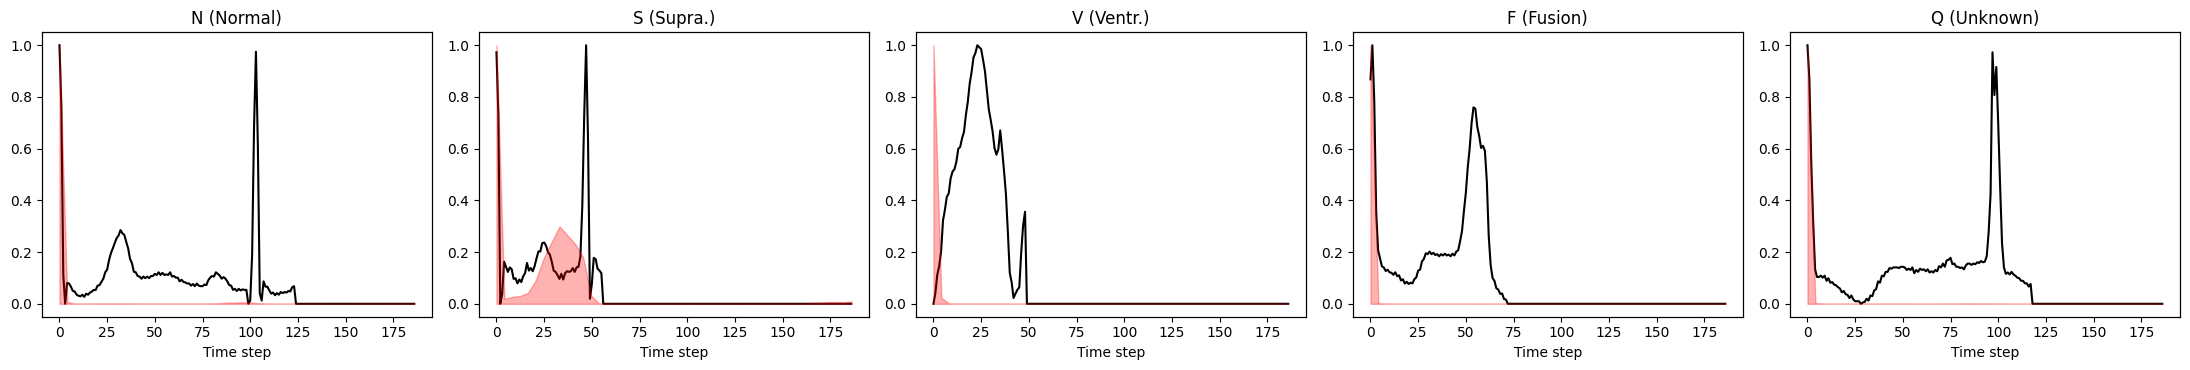

In [18]:
model_att.eval()
y_pred_att = predict(model_att, test_loader)

fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
for label in range(5):
    # first test beat of this class that the model got right
    idx = np.where((y_test == label) & (y_pred_att == label))[0][0]
    beat = X_test[idx]                                   # (1, 187)

    with torch.no_grad():
        model_att(torch.tensor(beat[np.newaxis]).to(device))     # forward pass on 1 beat
    att = model_att.attention_weights[0].cpu().numpy()  # (46,)

    att_x = np.linspace(0, 186, len(att))                # positions of the 46 steps on the 187 axis

    ax = axes[label]
    ax.plot(beat[0], color="black", label="ECG")
    ax2 = ax.twinx()
    ax2.fill_between(att_x, att, color="red", alpha=0.3, label="Attention")
    ax2.set_yticks([])
    ax.set_title(CLASS_NAMES[label])
    ax.set_xlabel("Time step")

plt.tight_layout()
plt.show()

In [19]:
sqrt_weights = np.sqrt(class_weights)
print(pd.DataFrame({"Class": CLASS_NAMES, "Balanced": class_weights.round(2), "Sqrt": sqrt_weights.round(2)}))

sqrt_weights_tensor = torch.tensor(sqrt_weights, dtype=torch.float32).to(device)

         Class  Balanced  Sqrt
0   N (Normal)      0.24  0.49
1   S (Supra.)      7.88  2.81
2   V (Ventr.)      3.03  1.74
3   F (Fusion)     27.31  5.23
4  Q (Unknown)      2.72  1.65


Epoch  1/30 | train loss 0.9949 | val macro F1 0.6250


Epoch  2/30 | train loss 0.4656 | val macro F1 0.7647


Epoch  3/30 | train loss 0.3507 | val macro F1 0.7665


Epoch  4/30 | train loss 0.2934 | val macro F1 0.7969


Epoch  5/30 | train loss 0.2520 | val macro F1 0.8210


...

Epoch 26/30 | train loss 0.0865 | val macro F1 0.8644


Epoch 27/30 | train loss 0.0957 | val macro F1 0.8863


Epoch 28/30 | train loss 0.0877 | val macro F1 0.8986


Epoch 29/30 | train loss 0.0843 | val macro F1 0.9135


Epoch 30/30 | train loss 0.0799 | val macro F1 0.8634

Best val macro F1: 0.9135 | training time: 134 s


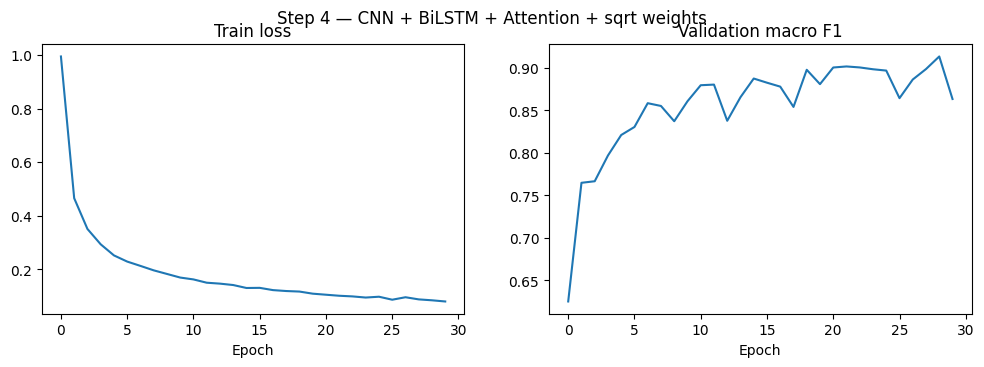

In [20]:
torch.manual_seed(42)
model_final = CNNBiLSTMAttention()           # same architecture as Step 3

model_final, history_final, time_final = train_model(model_final, epochs=30, class_weights=sqrt_weights_tensor)
plot_history(history_final, "Step 4 — CNN + BiLSTM + Attention + sqrt weights")

4. CNN+BiLSTM+Att + sqrt weights  ->  Test accuracy: 0.9769 | Test macro F1: 0.8831

              precision    recall  f1-score   support

  N (Normal)      0.990     0.985     0.988     18118
  S (Supra.)      0.727     0.781     0.753       556
  V (Ventr.)      0.946     0.957     0.952      1448
  F (Fusion)      0.684     0.802     0.739       162
 Q (Unknown)      0.981     0.989     0.985      1608

    accuracy                          0.977     21892
   macro avg      0.866     0.903     0.883     21892
weighted avg      0.978     0.977     0.977     21892



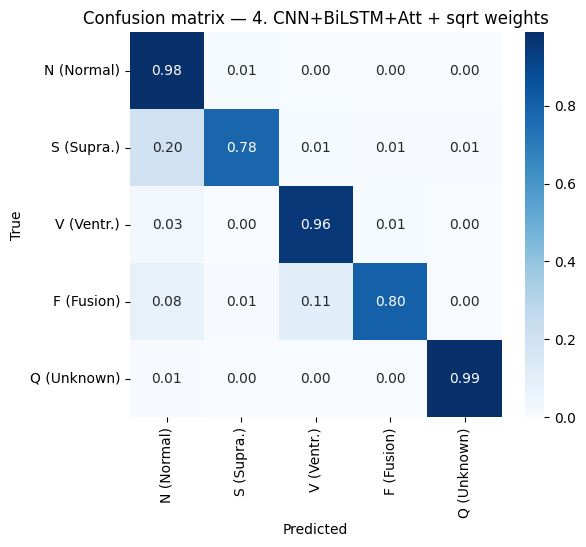

,Model,Accuracy,Macro F1,Recall N,Recall S,Recall V,Recall F,Recall Q,Params,Train time (s)
0,1. Simple CNN (baseline),0.959346,0.775585,0.988630,0.437050,0.888812,0.388889,0.930970,17477,43
1,2. Simple CNN + class weights,0.872054,0.661183,0.873496,0.728417,0.839779,0.839506,0.937811,17477,42
2,3. CNN + BiLSTM + Attention,0.978577,0.887445,0.993873,0.663669,0.937845,0.709877,0.978856,85766,58
3,4. CNN+BiLSTM+Att + sqrt weights,0.976887,0.883112,0.984987,0.780576,0.957182,0.802469,0.988806,85766,134


In [21]:
evaluate_model(model_final, "4. CNN+BiLSTM+Att + sqrt weights", time_final)

In [22]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, channels, kernel_size=5, padding=2)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size=5, padding=2)
        self.bn2 = nn.BatchNorm1d(channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + x                  # skip connection: add the input back
        return self.relu(out)


class ResNet1D(nn.Module):
    def __init__(self, n_classes=5, channels=32, n_blocks=5):
        super().__init__()
        self.first_conv = nn.Conv1d(1, channels, kernel_size=5, padding=2)

        layers = []
        for _ in range(n_blocks):
            layers.append(ResidualBlock(channels))
            layers.append(nn.MaxPool1d(kernel_size=5, stride=2))
        self.blocks = nn.Sequential(*layers)

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(channels, 32), nn.ReLU(),
            nn.Linear(32, n_classes),
        )

    def forward(self, x):            # x: (batch, 1, 187)
        x = self.first_conv(x)       # (batch, 32, 187)
        x = self.blocks(x)           # (batch, 32, 2)
        x = self.pool(x).flatten(1)  # (batch, 32)
        return self.classifier(x)    # (batch, 5)


torch.manual_seed(42)
model_resnet = ResNet1D()
print(model_resnet)
print("Trainable parameters:", sum(p.numel() for p in model_resnet.parameters()))

ResNet1D(
  (first_conv): Conv1d(1, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (blocks): Sequential(
    (0): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU()
    )
    (1): MaxPool1d(kernel_size=5, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ResidualBlock(
      (conv1): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU()
    )
    (3): MaxPool1d(kernel_size=5,

Epoch  1/30 | train loss 0.3274 | val macro F1 0.7747


Epoch  2/30 | train loss 0.1895 | val macro F1 0.8496


Epoch  3/30 | train loss 0.1514 | val macro F1 0.8618


Epoch  4/30 | train loss 0.1273 | val macro F1 0.8673


Epoch  5/30 | train loss 0.1163 | val macro F1 0.9077


...

Epoch 26/30 | train loss 0.0291 | val macro F1 0.9249


Epoch 27/30 | train loss 0.0313 | val macro F1 0.9218


Epoch 28/30 | train loss 0.0262 | val macro F1 0.9208


Epoch 29/30 | train loss 0.0293 | val macro F1 0.9158


Epoch 30/30 | train loss 0.0252 | val macro F1 0.9131

Best val macro F1: 0.9303 | training time: 220 s


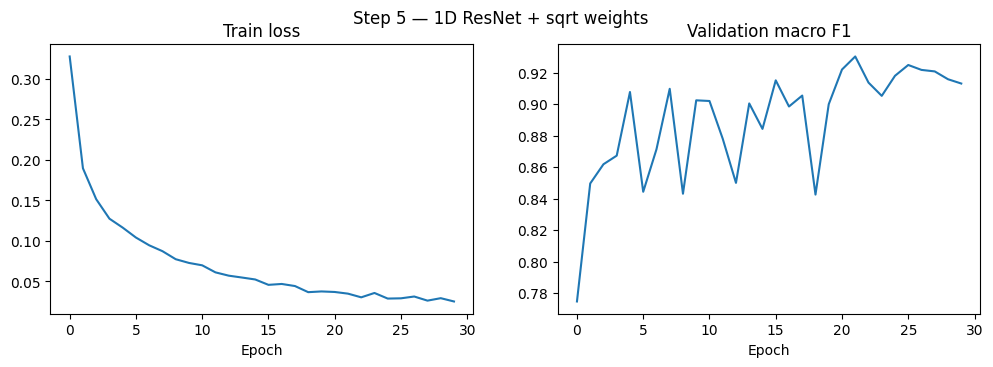

In [23]:
model_resnet, history_resnet, time_resnet = train_model(model_resnet, epochs=30, class_weights=sqrt_weights_tensor)
plot_history(history_resnet, "Step 5 — 1D ResNet + sqrt weights")

5. 1D ResNet + sqrt weights  ->  Test accuracy: 0.9855 | Test macro F1: 0.9201

              precision    recall  f1-score   support

  N (Normal)      0.993     0.993     0.993     18118
  S (Supra.)      0.829     0.838     0.834       556
  V (Ventr.)      0.969     0.961     0.965      1448
  F (Fusion)      0.777     0.858     0.815       162
 Q (Unknown)      0.996     0.992     0.994      1608

    accuracy                          0.986     21892
   macro avg      0.913     0.928     0.920     21892
weighted avg      0.986     0.986     0.986     21892



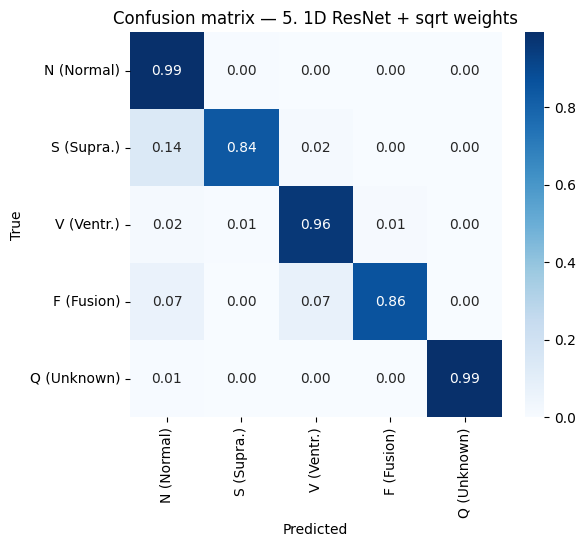

,Model,Accuracy,Macro F1,Recall N,Recall S,Recall V,Recall F,Recall Q,Params,Train time (s)
0,1. Simple CNN (baseline),0.959346,0.775585,0.988630,0.437050,0.888812,0.388889,0.930970,17477,43
1,2. Simple CNN + class weights,0.872054,0.661183,0.873496,0.728417,0.839779,0.839506,0.937811,17477,42
2,3. CNN + BiLSTM + Attention,0.978577,0.887445,0.993873,0.663669,0.937845,0.709877,0.978856,85766,58
3,4. CNN+BiLSTM+Att + sqrt weights,0.976887,0.883112,0.984987,0.780576,0.957182,0.802469,0.988806,85766,134
4,5. 1D ResNet + sqrt weights,0.985520,0.920061,0.992604,0.838129,0.960635,0.858025,0.991915,53573,220


In [24]:
evaluate_model(model_resnet, "5. 1D ResNet + sqrt weights", time_resnet)

### Step 5 — Observations
| | Step 4 (CNN + BiLSTM + Att) | **Step 5 (1D ResNet)** |
|---|---|---|
| Accuracy | 0.977 | **0.986** |
| **Macro F1** | 0.883 | **0.920** ↑ |
| Recall S / F | 0.78 / 0.80 | **0.84 / 0.86** ↑ |
| Precision S / F | 0.73 / 0.68 | **0.83 / 0.78** ↑ |
| Recall N / V / Q | 0.985 / 0.96 / 0.99 | **0.993 / 0.96 / 0.99** |
| Params | 86k | **54k** (fewer!) |
| Train time | ~2 min | ~3.7 min |

- **New best model:** macro F1 **0.883 → 0.920**, accuracy 98.6%.
- This time **recall AND precision both go up** for S and F — no trade-off. The model is simply better at telling the classes apart.
- It does this with **fewer parameters** (54k vs 86k) → the gain comes from the **design** (depth + skip connections), not from size.
- **Why does a pure CNN now beat the BiLSTM?** Each MaxPool halves the signal, so after 5 blocks one value "sees" the **whole beat** (large receptive field). A deep CNN can therefore also measure **timing** (like the RR interval) — which in Step 1 only the BiLSTM could do, because that CNN was too shallow. Skip connections + BatchNorm are what make this deep network trainable.
- Validation F1 jumps up and down between epochs (0.84–0.93). That is why `train_model` keeps the **best epoch** instead of the last one. A learning-rate scheduler could smooth this.
- Cost: slowest model to train (~3.7 min), but still fast on a GPU, and fast at prediction time.

**This is our final model.**

---
## Comparison of all steps

,Model,Accuracy,Macro F1,Recall N,Recall S,Recall V,Recall F,Recall Q,Params,Train time (s)
0,1. Simple CNN (baseline),0.959,0.776,0.989,0.437,0.889,0.389,0.931,17477,43
1,2. Simple CNN + class weights,0.872,0.661,0.873,0.728,0.840,0.840,0.938,17477,42
2,3. CNN + BiLSTM + Attention,0.979,0.887,0.994,0.664,0.938,0.710,0.979,85766,58
3,4. CNN+BiLSTM+Att + sqrt weights,0.977,0.883,0.985,0.781,0.957,0.802,0.989,85766,134
4,5. 1D ResNet + sqrt weights,0.986,0.920,0.993,0.838,0.961,0.858,0.992,53573,220


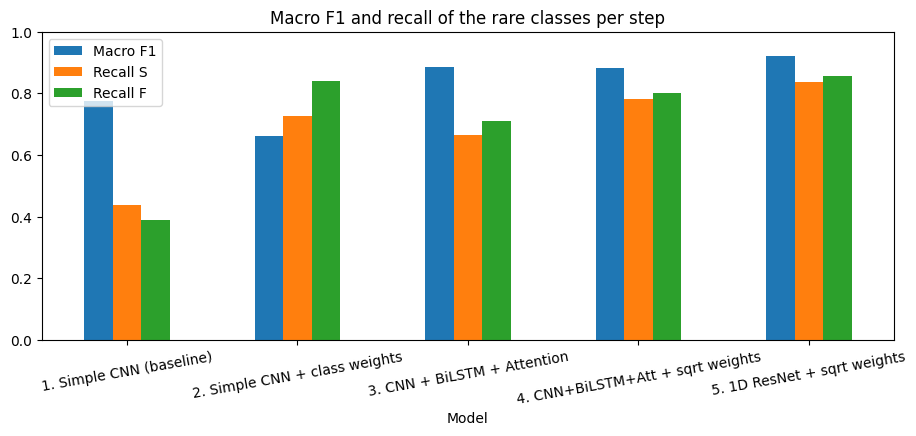

In [25]:
results_df = pd.DataFrame(results)
display(results_df.round(3))

results_df.set_index("Model")[["Macro F1", "Recall S", "Recall F"]].plot(kind="bar", figsize=(11, 4), rot=10)
plt.title("Macro F1 and recall of the rare classes per step")
plt.ylim(0, 1)
plt.show()

## Conclusion
| Step | Change | Macro F1 | Recall S | Recall F | What we learned |
|---|---|---|---|---|---|
| 1 | Simple 1D CNN | 0.776 | 0.44 | 0.39 | 96% accuracy hides poor rare-class performance |
| 2 | + balanced class weights | 0.661 | 0.73 | 0.84 | Too-strong weights → many false alarms (precision ~0.2) |
| 3 | CNN + BiLSTM + Attention | 0.887 | 0.66 | 0.71 | Sequence model captures **timing** (RR interval) → big jump in F1 |
| 4 | + √ class weights, 30 epochs | 0.883 | 0.78 | 0.80 | Same F1, higher recall of abnormal beats |
| 5 | **1D ResNet** + √ weights | **0.920** | **0.84** | **0.86** | Deep residual CNN beats all → **final model** |

**Key takeaways**
1. **Accuracy is misleading** on imbalanced medical data — macro F1 and per-class recall tell the real story.
2. **CNN vs sequence model:** a *shallow* CNN only sees local wave **shapes**, so adding a **BiLSTM** (order and timing) gave a big jump. But a **deep residual CNN** sees the whole beat too and was the best overall (0.920) — with fewer parameters and no recurrent layers. For short, fixed-length signals like a single heartbeat, a well-designed deep CNN is enough.
3. **Depth needs skip connections:** residual blocks + BatchNorm make an 11-layer CNN train easily.
4. **Class imbalance** must be handled carefully: full balancing over-corrects, **softer (√) weights** give a good recall/precision trade-off.
5. **Attention** helps but must be read carefully: on top of a BiLSTM it mostly points to where the summary is read, not directly to the important part of the signal.

**Possible future work:** data augmentation for rare classes (noise, scaling, shifting), a learning-rate scheduler to stabilise training, and testing the model on the PTB dataset (transfer learning, as in the original paper).